# Практика 5. Сравниваем GINE и GraphGPS на молекулах

**Задача:** по графу молекулы предсказать одно число — её химическую оценку.
Все слои и цикл обучения уже готовы. Ваша работа — разобраться в данных,
запустить одинаковый эксперимент для двух моделей и объяснить результат.

1. Посмотрите, как молекула хранится в ZINC.
2. Обучите локальную GNN и GraphGPS из готовых слоёв PyTorch Geometric.
3. Сравните ошибку и время. Укажите, какая модель лучше и на сколько.

Работаем на CPU. Сохранённые выводы можно читать без повторного обучения.
Для своего запуска в Colab выберите **Среда выполнения → Выполнить все**.

## 1. Окружение и настройки эксперимента

Достаточно PyTorch и PyTorch Geometric: дополнительные расширения для sampling не нужны.
В Colab PyTorch уже установлен, поэтому устанавливаем только PyG.

In [1]:
%pip -q install torch-geometric==2.8.0

In [2]:
import copy, os, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
from torch import nn
from torch_geometric.datasets import ZINC
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, GPSConv, global_mean_pool

# Меняйте настройки здесь, а не в цикле обучения.
EPOCHS = 10
SEEDS = [11, 22, 33]                 # три повторения с разной инициализацией
SIZES = {'train': 512, 'val': 128, 'test': 128}
BATCH_SIZE = 32
DEVICE = torch.device('cpu')
torch.set_num_threads(2)
ROOT = Path(os.environ.get('GNN_DATA_ROOT', str(Path.home()/'Downloads/gnn-course-data')))
ROOT.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

print('Устройство:', DEVICE, '| PyTorch:', torch.__version__)
print('Эпох:', EPOCHS, '| seed:', SEEDS, '| молекул:', SIZES)

Устройство: cpu | PyTorch: 2.8.0
Эпох: 10 | seed: [11, 22, 33] | молекул: {'train': 512, 'val': 128, 'test': 128}


## 2. Что находится в ZINC?

ZINC — набор молекулярных графов. В нашем варианте:

| Поле | Смысл |
|---|---|
| `x` | Код типа каждого атома, форма `[число атомов, 1]` |
| `edge_index` | Какие атомы соединены: пары индексов, форма `[2, число направленных связей]` |
| `edge_attr` | Код типа химической связи |
| `y` | Одно целевое число для всей молекулы — penalized logP |

Penalized logP — составная химическая оценка, учитывающая logP и штрафы за
синтетическую сложность и крупные циклы. Химию этой оценки в практике не изучаем.
Коды атомов и связей — категории, а не измеренные числовые величины.

Берём небольшие части официальных разбиений: **train** для обучения,
**val** для выбора лучшей эпохи, **test** для итоговой оценки.
При первой загрузке PyG скачает исходный архив целиком, даже для маленькой подвыборки.

In [3]:
# Выбор молекул фиксирован и одинаков для обеих моделей во всех запусках.
datasets = {split: ZINC(str(ROOT/'ZINC'), subset=True, split=split)
            for split in SIZES}
generator = torch.Generator().manual_seed(0)
graphs = {split: [ds[int(i)] for i in torch.randperm(len(ds), generator=generator)[:SIZES[split]]]
          for split, ds in datasets.items()}

print(pd.DataFrame([
    {'разбиение': split, 'молекул': len(items),
     'атомов в среднем': round(np.mean([g.num_nodes for g in items]), 1)}
    for split, items in graphs.items()
]).to_string(index=False))
g = graphs['train'][0]
print('\nПервая молекула:', g)
print('Коды первых атомов:', g.x[:5].flatten().tolist())
print('Первые связи (индексы атомов):', g.edge_index[:, :6].T.tolist())
print('Типы этих связей:', g.edge_attr[:6].flatten().tolist())
print('Целевое число y:', round(g.y.item(), 3))
assert all(g.y.numel() == 1 for items in graphs.values() for g in items)

разбиение  молекул  атомов в среднем
    train      512              23.0
      val      128              22.7
     test      128              22.6

Первая молекула: Data(x=[25, 1], edge_index=[2, 54], edge_attr=[54], y=[1])
Коды первых атомов: [0, 0, 0, 0, 0]
Первые связи (индексы атомов): [[0, 1], [1, 0], [1, 2], [1, 24], [2, 1], [2, 3]]
Типы этих связей: [1, 1, 2, 1, 2, 1]
Целевое число y: 2.399


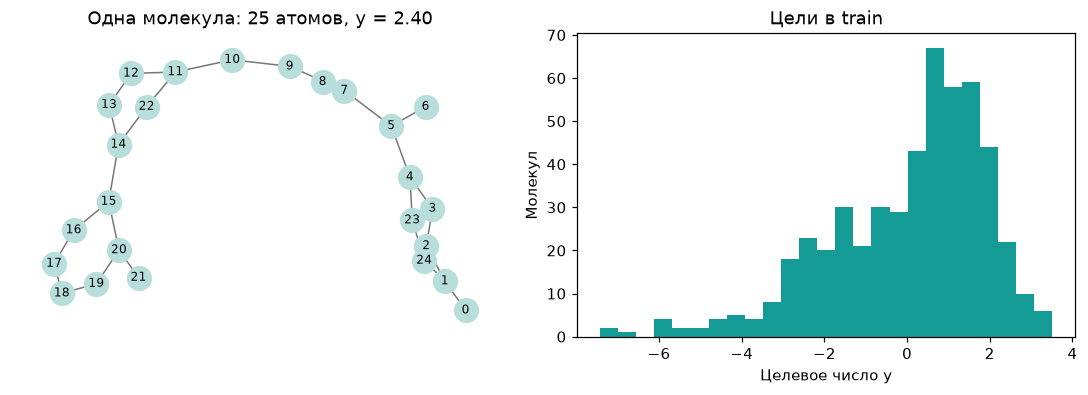

In [4]:
# Один и тот же рисунок показывает структуру графа и цель для всей молекулы.
G = nx.Graph()
G.add_nodes_from(range(g.num_nodes))
G.add_edges_from(g.edge_index.T.tolist())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
nx.draw_networkx(G, pos=nx.spring_layout(G, seed=0), ax=axes[0],
                 node_size=240, font_size=8, node_color='#b7deda', edge_color='#777777')
axes[0].set_title(f'Одна молекула: {g.num_nodes} атомов, y = {g.y.item():.2f}')
axes[0].axis('off')
axes[1].hist([item.y.item() for item in graphs['train']], bins=25, color='#159b95')
axes[1].set(xlabel='Целевое число y', ylabel='Молекул', title='Цели в train')
plt.tight_layout()
plt.show()

**Проверьте понимание:** что обозначают кружки и линии? Где хранится ответ:
у каждого атома или у всей молекулы? Почему коды атомов передаём в Embedding?

## 3. Две модели из готовых слоёв

- **GINE** — локальная GNN: каждый атом получает сообщения соседей с учётом типа связи.
- **GraphGPS** — та же GINE в локальной ветви плюс глобальное внимание внутри молекулы.
  `GPSConv` сам разделяет молекулы по `batch`, поэтому атомы разных молекул не смешиваются.

Общий путь: **коды атомов → векторы → два слоя → усреднение по атомам → одно число**.
В обоих вариантах одинаковы данные, ширина векторов, число слоёв и бюджет обучения.
GraphGPS содержит больше параметров, нормировки и дополнительные MLP,
поэтому сравниваем две конфигурации целиком. Этот опыт не выделяет чистый эффект attention.
Отдельные позиционные и структурные кодировки в этой короткой практике не добавляем.

In [5]:
class MoleculeModel(nn.Module):
    def __init__(self, use_gps=False):
        super().__init__()
        self.atom = nn.Embedding(28, 32)  # код атома → обучаемый вектор
        self.bond = nn.Embedding(4, 32)   # код связи → обучаемый вектор
        self.layers = nn.ModuleList()
        for _ in range(2):
            mlp = nn.Sequential(nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 32))
            local = GINEConv(mlp)        # готовый слой с признаками связей
            layer = GPSConv(32, local, heads=4, attn_type='multihead', dropout=0.0) if use_gps else local
            self.layers.append(layer)
        self.head = nn.Linear(32, 1)
        self.use_gps = use_gps

    def forward(self, batch):
        x = self.atom(batch.x.flatten())
        bonds = self.bond(batch.edge_attr.flatten())
        for layer in self.layers:
            if self.use_gps:
                x = layer(x, batch.edge_index, batch=batch.batch, edge_attr=bonds)
            else:
                x = layer(x, batch.edge_index, edge_attr=bonds).relu()
        # batch.batch хранит номер молекулы для каждого атома.
        graph_vectors = global_mean_pool(x, batch.batch)
        return self.head(graph_vectors).flatten()  # одно число на молекулу

for name, use_gps in [('GINE', False), ('GraphGPS', True)]:
    model = MoleculeModel(use_gps)
    print(name, '— параметров:', sum(p.numel() for p in model.parameters()))

GINE — параметров: 5281
GraphGPS — параметров: 22497


## 4. Ставим эксперимент и обучаем

**Вопрос:** уменьшится ли ошибка, если вместо двух локальных GINE-слоёв взять два GPS-слоя?

Фиксируем 10 эпох, Adam с шагом 0.001, одинаковые разбиения и порядок train-батчей
в парных запусках. Три seed дают представление о разбросе результатов.
Лучшую эпоху выбираем только по validation MAE, затем замораживаем веса.
Test смотрим после завершения обучения всех конфигураций.

**MAE** — средняя абсолютная разница между прогнозом и правильным числом.
Например, прогноз 2 при цели 3 даёт ошибку 1. Чем меньше MAE, тем лучше.

In [6]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_error, count = 0.0, 0
    for batch in loader:
        batch = batch.to(DEVICE)
        total_error += (model(batch) - batch.y.flatten()).abs().sum().item()
        count += batch.num_graphs
    return total_error / count

val_loader = DataLoader(graphs['val'], batch_size=64, shuffle=False)
test_loader = DataLoader(graphs['test'], batch_size=64, shuffle=False)

def train_one(use_gps, seed):
    set_seed(seed)
    model = MoleculeModel(use_gps).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loader = DataLoader(graphs['train'], batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    best_val, best_weights, best_epoch = float('inf'), None, None
    history = []
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for batch in loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            loss = (model(batch) - batch.y.flatten()).abs().mean()
            loss.backward()
            optimizer.step()
        val_mae = evaluate(model, val_loader)
        history.append(val_mae)
        if val_mae < best_val:
            best_val, best_epoch = val_mae, epoch
            best_weights = copy.deepcopy(model.state_dict())
    elapsed = time.perf_counter() - start
    model.load_state_dict(best_weights)
    return model, best_val, best_epoch, elapsed, history

runs, trained_models, histories = [], [], []
for seed in SEEDS:
    for name, use_gps in [('GINE', False), ('GraphGPS', True)]:
        model, val_mae, epoch, seconds, history = train_one(use_gps, seed)
        runs.append({'model': name, 'seed': seed, 'val_mae': val_mae,
                     'best_epoch': epoch, 'seconds': seconds})
        trained_models.append(model)
        histories.append(history)
        print(f'{name}, seed={seed}: validation MAE={val_mae:.3f}, эпоха={epoch}, {seconds:.2f} с')

GINE, seed=11: validation MAE=0.901, эпоха=10, 0.36 с
GraphGPS, seed=11: validation MAE=0.551, эпоха=8, 1.31 с
GINE, seed=22: validation MAE=0.875, эпоха=10, 0.34 с
GraphGPS, seed=22: validation MAE=0.553, эпоха=10, 1.37 с
GINE, seed=33: validation MAE=0.939, эпоха=10, 0.34 с
GraphGPS, seed=33: validation MAE=0.502, эпоха=9, 1.30 с


## 5. Какая модель лучше и на сколько?

Теперь оцениваем зафиксированные модели на test. Сравним среднюю MAE по трём запускам
и её стандартное отклонение. Также проверим простой ориентир: всегда предсказывать
среднее целевое число из train, не глядя на граф.

Все запуски:
   model  seed  val_mae  best_epoch  seconds  test_mae
    GINE    11    0.901          10    0.362     0.883
GraphGPS    11    0.551           8    1.310     0.586
    GINE    22    0.875          10    0.340     0.922
GraphGPS    22    0.553          10    1.372     0.540
    GINE    33    0.939          10    0.340     0.994
GraphGPS    33    0.502           9    1.300     0.505

Средние результаты:
          val_mae  test_mae  test_std  seconds
model                                         
GINE        0.905     0.933     0.056    0.348
GraphGPS    0.535     0.544     0.040    1.328
Прогноз среднего train: test MAE=1.610

В этом эксперименте GraphGPS лучше: средняя test MAE ниже на 0.389 (41.7%).
Среднее время обучения с validation: GraphGPS — 1.33 с; GINE — 0.35 с.


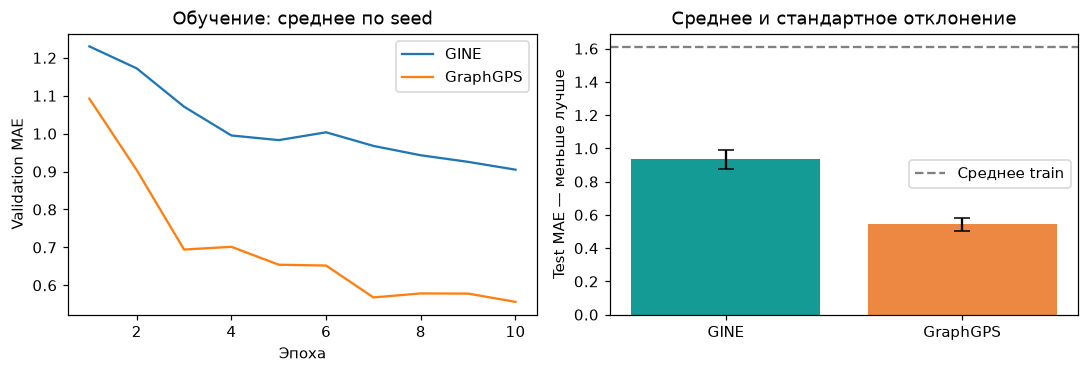

In [7]:
for row, model in zip(runs, trained_models):
    row['test_mae'] = evaluate(model, test_loader)
results = pd.DataFrame(runs)
summary = results.groupby('model', sort=False).agg(
    val_mae=('val_mae', 'mean'), test_mae=('test_mae', 'mean'),
    test_std=('test_mae', 'std'), seconds=('seconds', 'mean'))

train_mean = np.mean([g.y.item() for g in graphs['train']])
baseline_mae = np.mean([abs(g.y.item() - train_mean) for g in graphs['test']])
print('Все запуски:')
print(results.round(3).to_string(index=False))
print('\nСредние результаты:')
print(summary.round(3).to_string())
print(f'Прогноз среднего train: test MAE={baseline_mae:.3f}')

best = summary['test_mae'].idxmin()
other = next(name for name in summary.index if name != best)
difference = summary.loc[other, 'test_mae'] - summary.loc[best, 'test_mae']
percent = difference / summary.loc[other, 'test_mae'] * 100
print(f'\nВ этом эксперименте {best} лучше: средняя test MAE ниже на {difference:.3f} ({percent:.1f}%).')
print(f'Среднее время обучения с validation: {best} — {summary.loc[best, "seconds"]:.2f} с; '
      f'{other} — {summary.loc[other, "seconds"]:.2f} с.')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name in summary.index:
    curves = [history for row, history in zip(runs, histories) if row['model'] == name]
    axes[0].plot(range(1, EPOCHS + 1), np.mean(curves, axis=0), label=name)
axes[0].set(xlabel='Эпоха', ylabel='Validation MAE', title='Обучение: среднее по seed')
axes[0].legend()
axes[1].bar(summary.index, summary.test_mae, yerr=summary.test_std,
            capsize=5, color=['#159b95', '#ed8842'])
axes[1].axhline(baseline_mae, linestyle='--', color='gray', label='Среднее train')
axes[1].set(ylabel='Test MAE — меньше лучше', title='Среднее и стандартное отклонение')
axes[1].legend()
plt.tight_layout()
plt.show()
# Сохраняем числа, чтобы выводы в лекции совпадали с выполненным экспериментом.
report = {'epochs': EPOCHS, 'seeds': SEEDS, 'sizes': SIZES,
          'torch': torch.__version__, 'device': str(DEVICE),
          'runs': runs, 'summary': summary.reset_index().to_dict('records'),
          'baseline_mae': float(baseline_mae), 'best': best,
          'difference': float(difference), 'percent': float(percent)}
report_path = Path(os.environ.get('GNN_L05_REPORT', 'practice05_results.json'))
report_path.write_text(__import__('json').dumps(report, ensure_ascii=False, indent=2))

## 6. Ваш вывод

Ответьте по таблице и графику:

1. Какая модель получила меньшую среднюю test MAE? На сколько единиц и процентов?
2. Превзошли ли модели прогноз среднего train? Каков разброс по seed?
3. Сколько дополнительного времени потребовала GraphGPS? Оправдано ли это уменьшением ошибки?
4. Что изменится, если увеличить число обучающих молекул?

**Один дополнительный опыт:** увеличьте только `SIZES['train']` с 512 до 1024,
сохранив остальные настройки и тот же набор val/test. Повторите запуск и сравните вывод.
Рассматривайте это как заранее запланированное сравнение; не подбирайте настройки по test.

Это учебная подвыборка и короткое обучение. Результат относится к этим конфигурациям
и условиям; три seed не дают общего рейтинга архитектур.

Источники: [данные ZINC](https://pytorch-geometric.readthedocs.io/en/2.8.0/generated/torch_geometric.datasets.ZINC.html),
[GINEConv](https://pytorch-geometric.readthedocs.io/en/2.8.0/generated/torch_geometric.nn.conv.GINEConv.html),
[GPSConv](https://pytorch-geometric.readthedocs.io/en/2.8.0/generated/torch_geometric.nn.conv.GPSConv.html).